# AI 1 · Is the timetable speed error actually a problem?

gtfs2emis takes bus speeds from the GTFS timetable. This notebook answers two questions with MBTA data:

**A. How often, and by how much, do real MBTA buses differ from the timetable?**
All routes, all trips with recorded times, January 2022 – December 2025.

**B. Does the difference change the emission estimate?**
For two months (March 2024 and October 2025), every recorded segment gets a road distance from the GTFS route shapes,
so we know its timetable speed and its real speed. We then compute emissions twice with the emission factors that
gtfs2emis uses for the MBTA fleet (EPA MOVES, via `ef_usa_moves`): once with timetable speeds (what gtfs2emis does
today) and once with real speeds (what AI 1 aims to provide). The difference is the error caused by timetable speeds.

| Term | Meaning |
|---|---|
| **Segment** | The road between two consecutive *timepoints* (key stops where MBTA records times) of one trip |
| **Mid-route segment / last segment** | The last segment ends at the trip's final timepoint; all others are mid-route |
| **Speed factor** | scheduled time ÷ actual time = real speed ÷ timetable speed (1 = on timetable, < 1 = slower) |
| **Time-weighted factor** | total scheduled time ÷ total actual time: the factor of the average speed |
| **Trip running time** | time from the first to the last mid-route timepoint (excludes the padded last segment) |

## Setup
**Kaggle:** *Add Input* → the MBTA arrival/departure dataset and the GTFS feeds `20240313` and `20251014`
(zip or unzipped). Missing feeds are downloaded if Internet is on; otherwise that month is skipped in part B.
**Locally:** reads `data/raw/` (GTFS zips in `data/raw/gtfs_archive/`), writes to `data/interim/timetable_error_impact/`.
Months are processed one at a time; peak memory is about 2–3 GB.

In [1]:
from pathlib import Path
import gc, io, re, time, urllib.request, zipfile
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

print("polars", pl.__version__)
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(220); pl.Config.set_float_precision(3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    INPUT, OUT = Path("/kaggle/input"), Path("/kaggle/working/timetable_error_impact")
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
    INPUT, OUT = ROOT / "data" / "raw", ROOT / "data" / "interim" / "timetable_error_impact"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

FEEDS = {"2024-03": "20240313", "2025-10": "20251014"}   # month analysed in part B -> GTFS feed used for distances

FILE_RE = re.compile(r"MBTA-Bus-Arrival-Departure-Times_(\d{4}-\d{2})\.csv$")
sources = {}
for z in sorted(INPUT.rglob("*.zip")):
    try:
        for name in zipfile.ZipFile(z).namelist():
            if m := FILE_RE.search(name):
                sources[m.group(1)] = ("zip", z, name)
    except zipfile.BadZipFile:
        pass
for f in sorted(INPUT.rglob("*.csv")):
    if m := FILE_RE.search(f.name):
        sources[m.group(1)] = ("csv", f, None)
sources = dict(sorted(sources.items()))
assert sources, f"No MBTA-Bus-Arrival-Departure-Times_YYYY-MM.csv files (or zips containing them) under {INPUT}"
MONTHS = list(sources)
print(f"{len(MONTHS)} months: {MONTHS[0]} -> {MONTHS[-1]}")

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

polars 2.0.0
48 months: 2022-01 -> 2025-12


## Load (one pass over all months, cached)
For every month and route: counts of segments slower/faster than the timetable, total scheduled and actual time,
and trip running times. For the two part-B months, the individual segments (with stop IDs) are also kept.

In [2]:
AGG_SEG_P, AGG_TRIP_P = OUT / "agg_segments.parquet", OUT / "agg_trips.parquet"
seg_month_path = lambda m: OUT / f"segments_{m}.parquet"
TRIP = ["service_date", "half_trip_id"]

def open_month(month):
    kind, path, member = sources[month]
    return path if kind == "csv" else zipfile.ZipFile(path).read(member)

def seconds_of_day(col):  # "1900-01-01 06:05:00.000" (2022) or "1900-01-01T06:05:00Z" (later) -> seconds into service day
    ts = (pl.col(col).str.replace("T", " ").str.replace("Z", "").str.slice(0, 19)
          .str.strptime(pl.Datetime, "%Y-%m-%d %H:%M:%S", strict=False))
    return (ts - pl.datetime(1900, 1, 1)).dt.total_seconds().cast(pl.Int32)

def process_month(month):
    d = (pl.read_csv(open_month(month), infer_schema=False, null_values=["NA", ""],
                     columns=["service_date", "route_id", "direction_id", "half_trip_id", "stop_id",
                              "time_point_order", "point_type", "scheduled", "actual"])
           .filter(pl.col("half_trip_id").is_not_null())
           .with_columns(sched_s=seconds_of_day("scheduled"), act_s=seconds_of_day("actual"),
                         order=pl.col("time_point_order").cast(pl.Int16))
           .drop("scheduled", "actual", "time_point_order")
           .unique(subset=TRIP + ["order"], keep="first").sort(TRIP + ["order"]))
    nx = lambda c: pl.col(c).shift(-1).over(TRIP)
    seg = (d.with_columns(to_stop=nx("stop_id"), to_type=nx("point_type"), se=nx("sched_s"), ae=nx("act_s"))
             .filter(pl.col("to_stop").is_not_null())
             .select("route_id", "direction_id", "service_date", from_stop="stop_id", to_stop="to_stop",
                     is_last=(pl.col("to_type") == "Endpoint"),
                     hour=((pl.col("sched_s") // 3600) % 24).cast(pl.Int8),
                     sched=(pl.col("se") - pl.col("sched_s")).cast(pl.Int64),
                     act=(pl.col("ae") - pl.col("act_s")).cast(pl.Int64))
             .filter(pl.col("act").is_not_null() & (pl.col("sched") > 0) & (pl.col("act") > 0))
             .with_columns(f=pl.col("sched") / pl.col("act"),
                           weekday=pl.col("service_date").str.to_date().dt.weekday() <= 5)
             .filter(pl.col("f").is_between(0.2, 5)))
    if month in FEEDS:
        seg.drop("f").write_parquet(seg_month_path(month))
    seg_agg = (seg.group_by("route_id", "is_last", "weekday", "hour")
                  .agg(n=pl.len(), slower10=(pl.col("f") < 1 / 1.1).sum(), faster10=(pl.col("f") > 1.1).sum(),
                       slower25=(pl.col("f") < 1 / 1.25).sum(), faster25=(pl.col("f") > 1.25).sum(),
                       sched=pl.col("sched").sum(), act=pl.col("act").sum())
                  .with_columns(month=pl.lit(month)))
    trips = (d.group_by(TRIP).agg(pl.col("route_id").first(), n_tp=pl.len(),
                                  complete=pl.col("act_s").is_not_null().all() & (pl.col("point_type").last() == "Endpoint"),
                                  sched=(pl.col("sched_s").get(pl.len().cast(pl.Int64) - 2) - pl.col("sched_s").first()).cast(pl.Int64),
                                  act=(pl.col("act_s").get(pl.len().cast(pl.Int64) - 2) - pl.col("act_s").first()).cast(pl.Int64))
               .filter(pl.col("complete") & (pl.col("n_tp") >= 3) & (pl.col("sched") > 0) & (pl.col("act") > 0))
               .with_columns(r=pl.col("act") / pl.col("sched")).filter(pl.col("r").is_between(1 / 3, 3)))
    trip_agg = (trips.group_by("route_id")
                     .agg(n=pl.len(), longer10=(pl.col("r") > 1.1).sum(), shorter10=(pl.col("r") < 1 / 1.1).sum(),
                          late2=((pl.col("act") - pl.col("sched")) > 120).sum(),
                          late5=((pl.col("act") - pl.col("sched")) > 300).sum(),
                          early2=((pl.col("act") - pl.col("sched")) < -120).sum(),
                          sched=pl.col("sched").sum(), act=pl.col("act").sum())
                     .with_columns(month=pl.lit(month)))
    return seg_agg, trip_agg

done = AGG_SEG_P.exists() and AGG_TRIP_P.exists() and all(seg_month_path(m).exists() for m in FEEDS if m in sources)
if done:
    print("Loading cached tables from", OUT)
else:
    t0, sa, ta = time.time(), [], []
    for i, month in enumerate(MONTHS, 1):
        s_, t_ = process_month(month)
        sa.append(s_); ta.append(t_); gc.collect()
        print(f"\r{i}/{len(MONTHS)} {month} ({time.time() - t0:.0f}s)", end="")
    pl.concat(sa).write_parquet(AGG_SEG_P); pl.concat(ta).write_parquet(AGG_TRIP_P)
    print(f"\nDone in {time.time() - t0:.0f}s")

aseg = pl.read_parquet(AGG_SEG_P).with_columns(year=pl.col("month").str.slice(0, 4).cast(pl.Int16))
atrip = pl.read_parquet(AGG_TRIP_P).with_columns(year=pl.col("month").str.slice(0, 4).cast(pl.Int16))
print(f"Segments analysed: {aseg['n'].sum():,}   complete trips analysed: {atrip['n'].sum():,}   "
      f"routes: {aseg['route_id'].n_unique()}")

Loading cached tables from /home/omar-hazem/projects/Grad_project/transit-emissions-platform/data/interim/timetable_error_impact
Segments analysed: 85,756,122   complete trips analysed: 12,809,731   routes: 157


## Part A — How often do real buses differ from the timetable?
### A1. Headline numbers (all routes)

In [3]:
def trip_stats(df):
    return df.select(trips=pl.col("n").sum(),
                     pct_trips_10pct_slower=pl.col("longer10").sum() / pl.col("n").sum(),
                     pct_trips_within_10pct=1 - (pl.col("longer10").sum() + pl.col("shorter10").sum()) / pl.col("n").sum(),
                     pct_trips_10pct_faster=pl.col("shorter10").sum() / pl.col("n").sum(),
                     pct_trips_2min_late=pl.col("late2").sum() / pl.col("n").sum(),
                     pct_trips_5min_late=pl.col("late5").sum() / pl.col("n").sum(),
                     extra_min_per_trip=(pl.col("act").sum() - pl.col("sched").sum()) / pl.col("n").sum() / 60,
                     extra_bus_hours=(pl.col("act").sum() - pl.col("sched").sum()) / 3600)

def seg_stats(df):
    return df.select(segments=pl.col("n").sum(),
                     pct_10pct_slower=pl.col("slower10").sum() / pl.col("n").sum(),
                     pct_25pct_slower=pl.col("slower25").sum() / pl.col("n").sum(),
                     pct_within_10pct=1 - (pl.col("slower10").sum() + pl.col("faster10").sum()) / pl.col("n").sum(),
                     pct_10pct_faster=pl.col("faster10").sum() / pl.col("n").sum(),
                     pct_25pct_faster=pl.col("faster25").sum() / pl.col("n").sum(),
                     time_weighted_factor=pl.col("sched").sum() / pl.col("act").sum())

print("Trip running time (first → last mid-route timepoint) vs. timetable, by year")
trip_year = pl.concat([trip_stats(atrip.filter(pl.col("year") == y)).with_columns(year=pl.lit(y))
                       for y in sorted(atrip["year"].unique())] +
                      [trip_stats(atrip).with_columns(year=pl.lit("all"))], how="diagonal_relaxed")
print(trip_year.select("year", *[c for c in trip_year.columns if c != "year"]))

print("\nSegments vs. timetable (all years)")
seg_tab = pl.concat([seg_stats(aseg.filter(~pl.col("is_last"))).with_columns(part=pl.lit("mid-route")),
                     seg_stats(aseg.filter(pl.col("is_last"))).with_columns(part=pl.lit("last segment")),
                     seg_stats(aseg).with_columns(part=pl.lit("all segments"))])
seg_tab.select("part", *[c for c in seg_tab.columns if c != "part"])

Trip running time (first → last mid-route timepoint) vs. timetable, by year
shape: (5, 9)
┌──────┬──────────┬────────────────────────┬────────────────────────┬────────────────────────┬─────────────────────┬─────────────────────┬────────────────────┬─────────────────┐
│ year ┆ trips    ┆ pct_trips_10pct_slower ┆ pct_trips_within_10pct ┆ pct_trips_10pct_faster ┆ pct_trips_2min_late ┆ pct_trips_5min_late ┆ extra_min_per_trip ┆ extra_bus_hours │
│ ---  ┆ ---      ┆ ---                    ┆ ---                    ┆ ---                    ┆ ---                 ┆ ---                 ┆ ---                ┆ ---             │
│ str  ┆ u32      ┆ f64                    ┆ f64                    ┆ f64                    ┆ f64                 ┆ f64                 ┆ f64                ┆ f64             │
╞══════╪══════════╪════════════════════════╪════════════════════════╪════════════════════════╪═════════════════════╪═════════════════════╪════════════════════╪═════════════════╡
│ 2022 ┆ 3320026  ┆ 

part,segments,pct_10pct_slower,pct_25pct_slower,pct_within_10pct,pct_10pct_faster,pct_25pct_faster,time_weighted_factor
str,u32,f64,f64,f64,f64,f64,f64
"""mid-route""",72735259,0.468,0.327,0.218,0.315,0.197,0.907
"""last segment""",13020863,0.103,0.066,0.097,0.801,0.702,1.412
"""all segments""",85756122,0.412,0.287,0.199,0.388,0.274,0.989


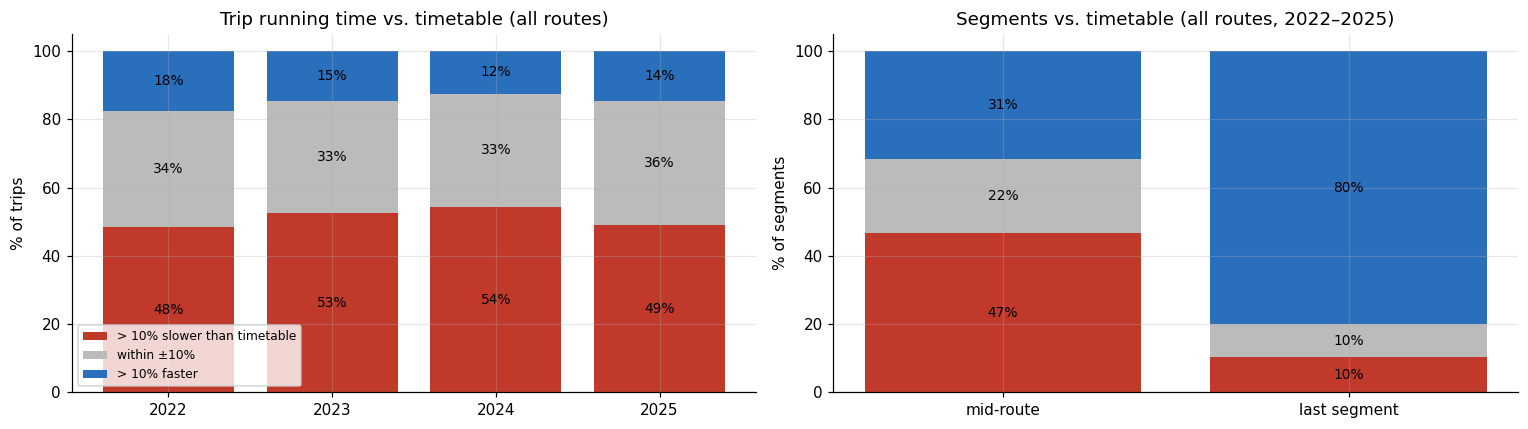

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ty = trip_year.filter(pl.col("year") != "all")
yrs = ty["year"].cast(pl.String).to_list()
bottom = np.zeros(len(yrs))
for col, label, color in [("pct_trips_10pct_slower", "> 10% slower than timetable", "#c0392b"),
                          ("pct_trips_within_10pct", "within ±10%", "#bbb"),
                          ("pct_trips_10pct_faster", "> 10% faster", "#2a6fbb")]:
    v = ty[col].to_numpy() * 100
    ax[0].bar(yrs, v, bottom=bottom, label=label, color=color)
    for x, b, h in zip(yrs, bottom, v):
        ax[0].text(x, b + h / 2, f"{h:.0f}%", ha="center", va="center", fontsize=9)
    bottom += v
ax[0].set_ylabel("% of trips"); ax[0].legend(loc="lower left", fontsize=8)
ax[0].set_title("Trip running time vs. timetable (all routes)")
st = seg_tab.filter(pl.col("part") != "all segments")
bottom = np.zeros(st.height)
for col, label, color in [("pct_10pct_slower", "> 10% slower", "#c0392b"), ("pct_within_10pct", "within ±10%", "#bbb"),
                          ("pct_10pct_faster", "> 10% faster", "#2a6fbb")]:
    v = st[col].to_numpy() * 100
    ax[1].bar(st["part"].to_list(), v, bottom=bottom, label=label, color=color)
    for x, b, h in zip(st["part"].to_list(), bottom, v):
        ax[1].text(x, b + h / 2, f"{h:.0f}%", ha="center", va="center", fontsize=9)
    bottom += v
ax[1].set_ylabel("% of segments"); ax[1].set_title("Segments vs. timetable (all routes, 2022–2025)")
plt.tight_layout(); savefig(fig, "A1_how_many_differ"); plt.show()

### A2. Is it a few routes, or the whole network?
Time-weighted factor of mid-route segments for each route (weekdays 2024, routes with at least 5,000 segments).
Each bar of the histogram counts routes.

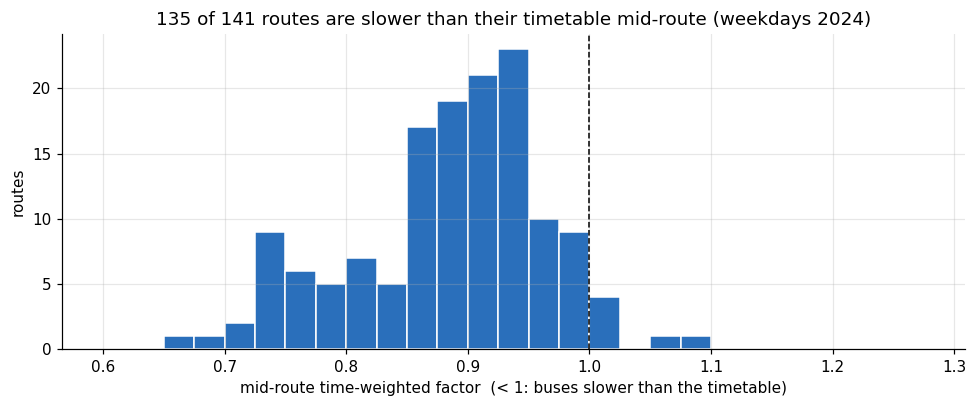

routes,slower_than_timetable,more_than_10pct_slower,more_than_20pct_slower,faster_than_timetable,median_route_factor
u32,u32,u32,u32,u32,f64
141,135,80,32,6,0.896


In [5]:
rt = (aseg.filter((pl.col("year") == 2024) & ~pl.col("is_last") & pl.col("weekday"))
          .group_by("route_id").agg(n=pl.col("n").sum(), f=pl.col("sched").sum() / pl.col("act").sum())
          .filter(pl.col("n") >= 5000))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(rt["f"], bins=np.arange(0.6, 1.3, 0.025), color="#2a6fbb", edgecolor="white")
ax.axvline(1, color="k", ls="--", lw=1)
ax.set_xlabel("mid-route time-weighted factor  (< 1: buses slower than the timetable)"); ax.set_ylabel("routes")
ax.set_title(f"{(rt['f'] < 1).sum()} of {rt.height} routes are slower than their timetable mid-route (weekdays 2024)")
plt.tight_layout(); savefig(fig, "A2_routes"); plt.show()
rt.select(routes=pl.len(), slower_than_timetable=(pl.col("f") < 1).sum(), more_than_10pct_slower=(pl.col("f") < 1 / 1.1).sum(),
          more_than_20pct_slower=(pl.col("f") < 1 / 1.2).sum(), faster_than_timetable=(pl.col("f") > 1).sum(),
          median_route_factor=pl.col("f").median())

### A3. When is the gap largest?
Network-wide mid-route factor by hour, weekdays, per year.

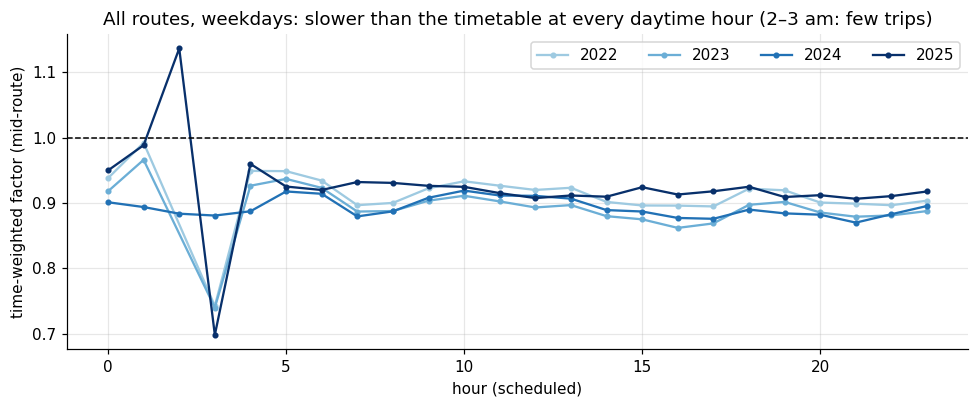

In [6]:
hr = (aseg.filter(~pl.col("is_last") & pl.col("weekday")).group_by("year", "hour")
          .agg(f=pl.col("sched").sum() / pl.col("act").sum()).sort("hour"))
fig, ax = plt.subplots(figsize=(9, 3.8))
for y, c in zip(sorted(hr["year"].unique()), ["#9ecae1", "#6baed6", "#2171b5", "#08306b"]):
    h = hr.filter(pl.col("year") == y)
    ax.plot(h["hour"], h["f"], marker=".", label=str(y), color=c)
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xlabel("hour (scheduled)"); ax.set_ylabel("time-weighted factor (mid-route)"); ax.legend(ncol=4)
ax.set_title("All routes, weekdays: slower than the timetable at every daytime hour (2–3 am: few trips)")
plt.tight_layout(); savefig(fig, "A3_hours"); plt.show()

## Part B — Does it change the emission estimate?

### Emission factors
gtfs2emis's US model (`ef_usa_moves`, EPA MOVES) gives an emission factor per km that depends on speed **in bins**
of 5 mph. The table below is the MBTA fleet average (NTD inventory: 1,050 buses, 83% diesel, 17% CNG, model years
2008–2020), generated in R with gtfs2emis 0.1.2 (`ef_usa_moves`, reference year 2020) — the same fleet table as the
team's gtfs2emis test. Bin edges were read from gtfs2emis at 0.01 km/h resolution.

In [7]:
EDGES_KMH = [4.01, 12.11, 20.11, 28.21, 36.21, 44.30, 52.30, 60.41, 68.41, 76.41]   # a speed >= edge falls in the next bin
EF = pl.DataFrame({   # MBTA fleet-weighted, g/km, one row per speed bin
    "bin_from_kmh": [0.0] + EDGES_KMH,
    "CO2": [3348.766, 1944.854, 1346.516, 1164.953, 1035.504, 949.313, 913.270, 847.635, 827.003, 811.459, 803.110],
    "NOx": [8.97060, 4.72984, 2.87485, 2.19371, 1.77335, 1.48379, 1.30095, 1.10726, 0.98313, 0.88662, 0.80971],
    "PM25": [0.024085, 0.014664, 0.010063, 0.008425, 0.007298, 0.006299, 0.005764, 0.004791, 0.004292, 0.003905, 0.003605]})
POLS = ["CO2", "NOx", "PM25"]
EF.with_columns(bin_to_kmh=pl.col("bin_from_kmh").shift(-1))

bin_from_kmh,CO2,NOx,PM25,bin_to_kmh
f64,f64,f64,f64,f64
0.000,3348.766,8.971,0.024,4.010
4.010,1944.854,4.730,0.015,12.110
12.110,1346.516,2.875,0.010,20.110
20.110,1164.953,2.194,0.008,28.210
28.210,1035.504,1.773,0.007,36.210
36.210,949.313,1.484,0.006,44.300
44.300,913.270,1.301,0.006,52.300
52.300,847.635,1.107,0.005,60.410
60.410,827.003,0.983,0.004,68.410


### Road distances from GTFS shapes
Each timepoint stop is projected onto the GTFS shapes of its route and direction; the distance of a segment is the
distance along the shape between its two stops (the most-used shape on which both stops lie within 60 m, in order).

In [8]:
def find_gtfs(feed):
    for z in INPUT.rglob(f"{feed}.zip"):
        return zipfile.ZipFile(z)
    for st in INPUT.rglob("shapes.txt"):
        if feed in str(st.parent):
            return st.parent
    target = OUT / f"{feed}.zip"
    if not target.exists():
        urllib.request.urlretrieve(f"https://cdn.mbtace.com/archive/{feed}.zip", target)
    return zipfile.ZipFile(target)

def reader(feed_src):
    def read(name):
        raw = feed_src.read(name) if isinstance(feed_src, zipfile.ZipFile) else (feed_src / name).read_bytes()
        return pl.read_csv(io.BytesIO(raw), infer_schema=False)
    return read

LAT0 = 42.35
def to_xy(lat, lon):  # metres, local equirectangular projection (accurate to <0.1% across Boston)
    return np.column_stack([(lon + 71.06) * np.cos(np.radians(LAT0)) * 111_320, (lat - LAT0) * 110_574])

def project(points_xy, stops_xy):
    """Distance along a polyline and offset from it, for each stop."""
    a, b = points_xy[:-1], points_xy[1:]
    ab = b - a
    seg_len = np.hypot(ab[:, 0], ab[:, 1])
    cum = np.concatenate([[0], np.cumsum(seg_len)])[:-1]
    ap = stops_xy[:, None, :] - a[None, :, :]
    t = np.clip((ap * ab[None]).sum(-1) / np.maximum(seg_len ** 2, 1e-9)[None], 0, 1)
    proj = a[None] + t[..., None] * ab[None]
    off = np.hypot(*(stops_xy[:, None, :] - proj).transpose(2, 0, 1))
    k = off.argmin(1)
    return cum[k] + t[np.arange(len(k)), k] * seg_len[k], off[np.arange(len(k)), k]

def segment_distances(feed, seg):
    read = reader(find_gtfs(feed))
    routes, trips, stops, shapes = read("routes.txt"), read("trips.txt"), read("stops.txt"), read("shapes.txt")
    short_to_id = dict(zip(routes["route_short_name"], routes["route_id"]))
    ids = set(routes["route_id"])
    rmap = {r: (r.lstrip("0") if r.lstrip("0") in ids else short_to_id.get(r)) for r in seg["route_id"].unique()}
    seg = seg.with_columns(gtfs_route=pl.col("route_id").replace_strict(rmap, default=None, return_dtype=pl.String),
                           dir=pl.when(pl.col("direction_id") == "Inbound").then(pl.lit("1")).otherwise(pl.lit("0")))
    pairs = seg.select("gtfs_route", "dir", "from_stop", "to_stop").unique().drop_nulls()
    use = trips.group_by("route_id", "direction_id", "shape_id").len("shape_trips")
    sxy = {r["stop_id"]: (float(r["stop_lat"]), float(r["stop_lon"])) for r in stops.select("stop_id", "stop_lat", "stop_lon").drop_nulls().iter_rows(named=True)}
    shp = {k[0]: g.sort(pl.col("shape_pt_sequence").cast(pl.Int64)) for k, g in shapes.group_by("shape_id")}
    rows = []
    for (route, dirn), p in pairs.group_by("gtfs_route", "dir"):
        st_ids = [s for s in set(p["from_stop"]) | set(p["to_stop"]) if s in sxy]
        if not st_ids:
            continue
        st_xy = to_xy(np.array([sxy[s][0] for s in st_ids]), np.array([sxy[s][1] for s in st_ids]))
        for sh in use.filter((pl.col("route_id") == route) & (pl.col("direction_id") == dirn)).iter_rows(named=True):
            g = shp.get(sh["shape_id"])
            if g is None or g.height < 2:
                continue
            along, off = project(to_xy(g["shape_pt_lat"].cast(pl.Float64).to_numpy(), g["shape_pt_lon"].cast(pl.Float64).to_numpy()), st_xy)
            rows += [(route, dirn, sh["shape_id"], sh["shape_trips"], s, a, o) for s, a, o in zip(st_ids, along, off)]
    pos = pl.DataFrame(rows, schema=["gtfs_route", "dir", "shape_id", "shape_trips", "stop", "along", "off"], orient="row")
    dist = (pairs.join(pos.rename({"stop": "from_stop", "along": "a1", "off": "o1"}), on=["gtfs_route", "dir", "from_stop"])
                 .join(pos.rename({"stop": "to_stop", "along": "a2", "off": "o2"}).drop("shape_trips"),
                       on=["gtfs_route", "dir", "shape_id", "to_stop"])
                 .filter((pl.col("o1") < 60) & (pl.col("o2") < 60) & (pl.col("a2") > pl.col("a1")))
                 .sort("shape_trips", descending=True)
                 .unique(["gtfs_route", "dir", "from_stop", "to_stop"], keep="first")
                 .select("gtfs_route", "dir", "from_stop", "to_stop", km=(pl.col("a2") - pl.col("a1")) / 1000))
    out = seg.join(dist, on=["gtfs_route", "dir", "from_stop", "to_stop"], how="left")
    return out, out["km"].is_not_null().mean()

def ef_lookup(speed_kmh):
    idx = np.searchsorted(np.array(EDGES_KMH), speed_kmh, side="right")
    return {p: EF[p].to_numpy()[idx] for p in POLS}

results, speed_samples = {}, {}
for month, feed in FEEDS.items():
    if not seg_month_path(month).exists():
        print(f"{month}: no arrival data, skipped"); continue
    try:
        seg_d, matched = segment_distances(feed, pl.read_parquet(seg_month_path(month)))
    except Exception as e:
        print(f"{month}: GTFS feed {feed} not available ({e}); skipped"); continue
    s = (seg_d.filter(pl.col("km").is_not_null() & (pl.col("km") >= 0.1))
              .with_columns(v_tt=pl.col("km") / (pl.col("sched") / 3600), v_act=pl.col("km") / (pl.col("act") / 3600))
              .filter(pl.col("v_tt").is_between(2, 80) & pl.col("v_act").is_between(2, 80)))
    e_tt, e_act = ef_lookup(s["v_tt"].to_numpy()), ef_lookup(s["v_act"].to_numpy())
    s = s.with_columns(*[pl.Series(f"{p}_tt", e_tt[p] * s["km"].to_numpy()) for p in POLS],
                       *[pl.Series(f"{p}_act", e_act[p] * s["km"].to_numpy()) for p in POLS],
                       bin_tt=pl.Series(np.searchsorted(EDGES_KMH, s["v_tt"].to_numpy(), side="right")),
                       bin_act=pl.Series(np.searchsorted(EDGES_KMH, s["v_act"].to_numpy(), side="right")))
    results[month] = s
    print(f"{month} (GTFS {feed}): {seg_d.height:,} segments, distance found for {matched:.1%}; "
          f"{s.height:,} kept (≥100 m, 2–80 km/h, as in transport_model)")

2024-03 (GTFS 20240313): 1,752,906 segments, distance found for 95.6%; 1,670,225 kept (≥100 m, 2–80 km/h, as in transport_model)


2025-10 (GTFS 20251014): 1,956,522 segments, distance found for 94.9%; 1,852,438 kept (≥100 m, 2–80 km/h, as in transport_model)


### B1. Timetable speed vs. real speed

2024-03
shape: (2, 7)
┌──────────────┬──────────┬─────────────┬───────────────┬────────────┬─────────────────────────┬────────────────────────┐
│ part         ┆ segments ┆ bus_km      ┆ timetable_kmh ┆ actual_kmh ┆ pct_different_moves_bin ┆ pct_real_in_slower_bin │
│ ---          ┆ ---      ┆ ---         ┆ ---           ┆ ---        ┆ ---                     ┆ ---                    │
│ str          ┆ u32      ┆ f64         ┆ f64           ┆ f64        ┆ f64                     ┆ f64                    │
╞══════════════╪══════════╪═════════════╪═══════════════╪════════════╪═════════════════════════╪════════════════════════╡
│ mid-route    ┆ 1408495  ┆ 1983967.975 ┆ 19.819        ┆ 17.574     ┆ 0.564                   ┆ 0.366                  │
│ last segment ┆ 261730   ┆ 452574.898  ┆ 14.382        ┆ 20.319     ┆ 0.746                   ┆ 0.061                  │
└──────────────┴──────────┴─────────────┴───────────────┴────────────┴─────────────────────────┴────────────────────────┘
20

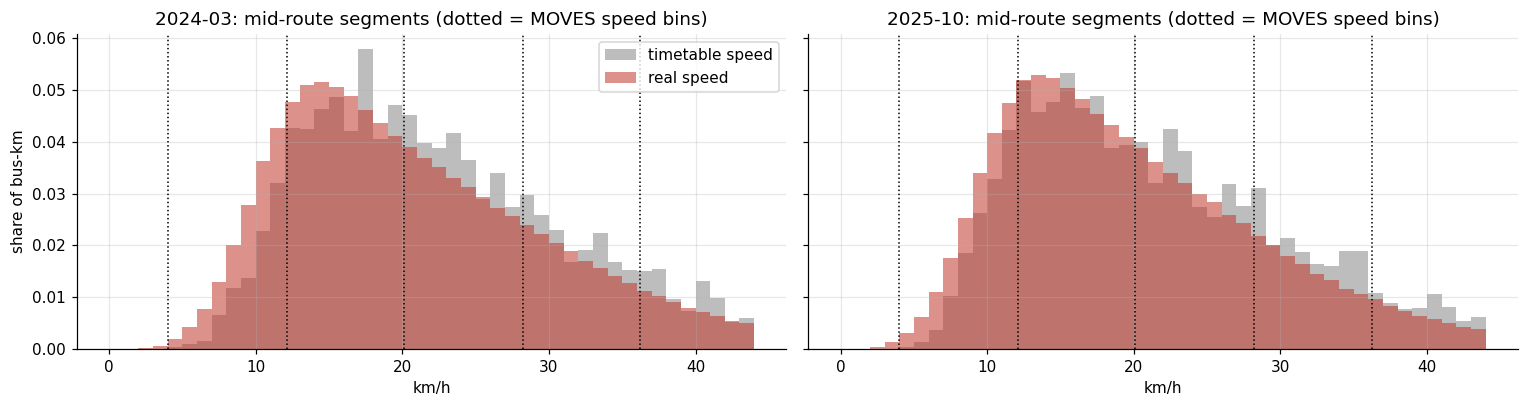

In [9]:
def speed_tab(s):
    return (s.with_columns(part=pl.when(pl.col("is_last")).then(pl.lit("last segment")).otherwise(pl.lit("mid-route")))
             .group_by("part").agg(segments=pl.len(), bus_km=pl.col("km").sum(),
                                   timetable_kmh=pl.col("km").sum() / (pl.col("sched").sum() / 3600),
                                   actual_kmh=pl.col("km").sum() / (pl.col("act").sum() / 3600),
                                   pct_different_moves_bin=(pl.col("bin_tt") != pl.col("bin_act")).mean(),
                                   pct_real_in_slower_bin=(pl.col("bin_act") < pl.col("bin_tt")).mean())
             .sort("part", descending=True))
for month, s in results.items():
    print(month); print(speed_tab(s))

fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 3.8), sharey=True, squeeze=False)
for ax, (month, s) in zip(axes[0], results.items()):
    mid = s.filter(~pl.col("is_last"))
    bins = np.arange(0, 45, 1)
    ax.hist(mid["v_tt"], bins=bins, weights=mid["km"], alpha=.55, color="#888", label="timetable speed", density=True)
    ax.hist(mid["v_act"], bins=bins, weights=mid["km"], alpha=.55, color="#c0392b", label="real speed", density=True)
    for e in EDGES_KMH[:5]:
        ax.axvline(e, color="k", ls=":", lw=1)
    ax.set_title(f"{month}: mid-route segments (dotted = MOVES speed bins)"); ax.set_xlabel("km/h")
axes[0][0].set_ylabel("share of bus-km"); axes[0][0].legend()
plt.tight_layout(); savefig(fig, "B1_speeds"); plt.show()

### B2. Emissions with timetable speeds vs. real speeds
Same segments, same distances, same fleet; only the speed differs. *Error* = (timetable − real) ÷ real.
A negative error means gtfs2emis with timetable speeds **underestimates** emissions.

In [10]:
def emis_tab(s, by=None):
    grp = [by] if by else []
    agg = [pl.col(f"{p}_{k}").sum() for p in POLS for k in ("tt", "act")]
    t = s.group_by(grp or pl.lit(1)).agg(pl.col("km").sum().alias("bus_km"), *agg)
    t = t.with_columns(*[((pl.col(f"{p}_tt") - pl.col(f"{p}_act")) / pl.col(f"{p}_act")).alias(f"{p}_error") for p in POLS])
    return t.drop("literal", strict=False)

part = pl.when(pl.col("is_last")).then(pl.lit("last segment")).otherwise(pl.lit("mid-route")).alias("part")
emis_all = []
for month, s in results.items():
    e = pl.concat([emis_tab(s.with_columns(part), "part"),
                   emis_tab(s).with_columns(part=pl.lit("whole trips"))], how="diagonal_relaxed")
    e = e.with_columns(month=pl.lit(month), CO2_tt_t=pl.col("CO2_tt") / 1e6, CO2_act_t=pl.col("CO2_act") / 1e6)
    emis_all.append(e.select("month", "part", "bus_km", "CO2_tt_t", "CO2_act_t", "CO2_error", "NOx_error", "PM25_error"))
emis_all = pl.concat(emis_all)
print("Total over the month (CO2 in tonnes)")
emis_all

Total over the month (CO2 in tonnes)


month,part,bus_km,CO2_tt_t,CO2_act_t,CO2_error,NOx_error,PM25_error
str,str,f64,f64,f64,f64,f64,f64
"""2024-03""","""mid-route""",1983967.975,2467.715,2600.068,-0.051,-0.082,-0.059
"""2024-03""","""last segment""",452574.898,651.021,553.256,0.177,0.299,0.207
"""2024-03""","""whole trips""",2436542.873,3118.736,3153.324,-0.011,-0.017,-0.012
"""2025-10""","""mid-route""",2201413.207,2833.443,2968.877,-0.046,-0.072,-0.053
"""2025-10""","""last segment""",479157.307,710.083,598.794,0.186,0.309,0.215
"""2025-10""","""whole trips""",2680570.514,3543.526,3567.670,-0.007,-0.011,-0.008


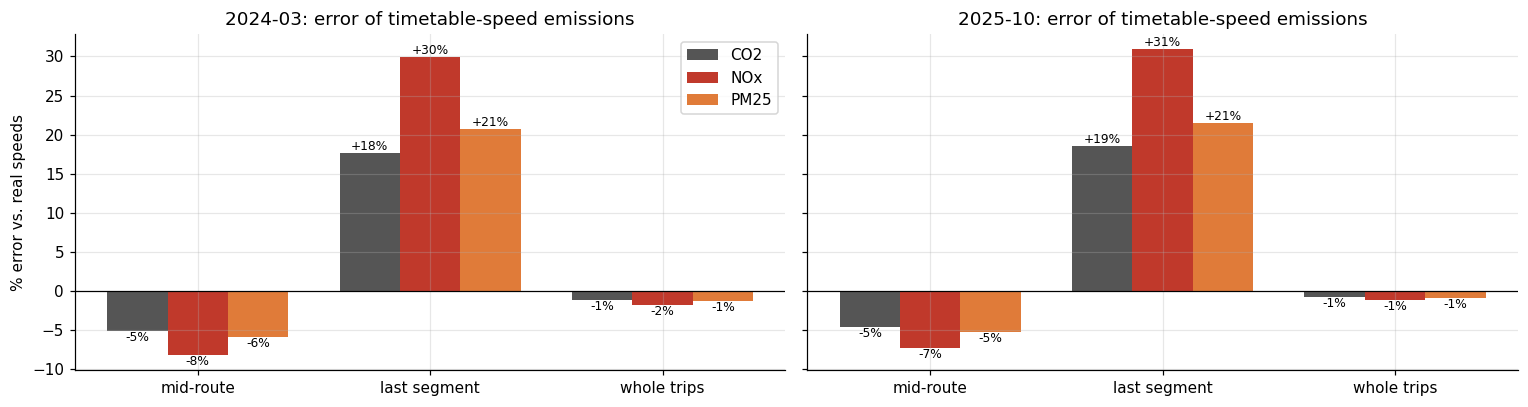

In [11]:
fig, axes = plt.subplots(1, len(results), figsize=(7 * len(results), 3.8), sharey=True, squeeze=False)
for ax, month in zip(axes[0], results):
    e = emis_all.filter(pl.col("month") == month)
    parts = e["part"].to_list()
    w = .26
    for k, (p, color) in enumerate(zip(POLS, ["#555", "#c0392b", "#e07b39"])):
        v = (e[f"{p}_error"] * 100).to_list()
        bars = ax.bar([i + (k - 1) * w for i in range(len(parts))], v, w, label=p, color=color)
        ax.bar_label(bars, fmt="%+.0f%%", fontsize=8)
    ax.axhline(0, color="k", lw=.8)
    ax.set_xticks(range(len(parts)), parts); ax.set_title(f"{month}: error of timetable-speed emissions")
axes[0][0].set_ylabel("% error vs. real speeds"); axes[0][0].legend()
plt.tight_layout(); savefig(fig, "B2_emission_error"); plt.show()

### B3. Errors where the platform shows them: per route, per segment, per hour
The platform shows emissions **by route, on maps by segment, and by time of day**. Do the opposite errors
(mid-route vs. last segment) also cancel at these levels?

2024-03: routes with |CO2 error| > 10%: 1% of 146; > 20%: 0%
2024-03: road segments with |CO2 error| > 10%: 40% of 1930; > 25%: 10%  (underestimated: 22%, overestimated: 18%)
2025-10: routes with |CO2 error| > 10%: 1% of 147; > 20%: 0%
2025-10: road segments with |CO2 error| > 10%: 40% of 1938; > 25%: 9%  (underestimated: 22%, overestimated: 18%)


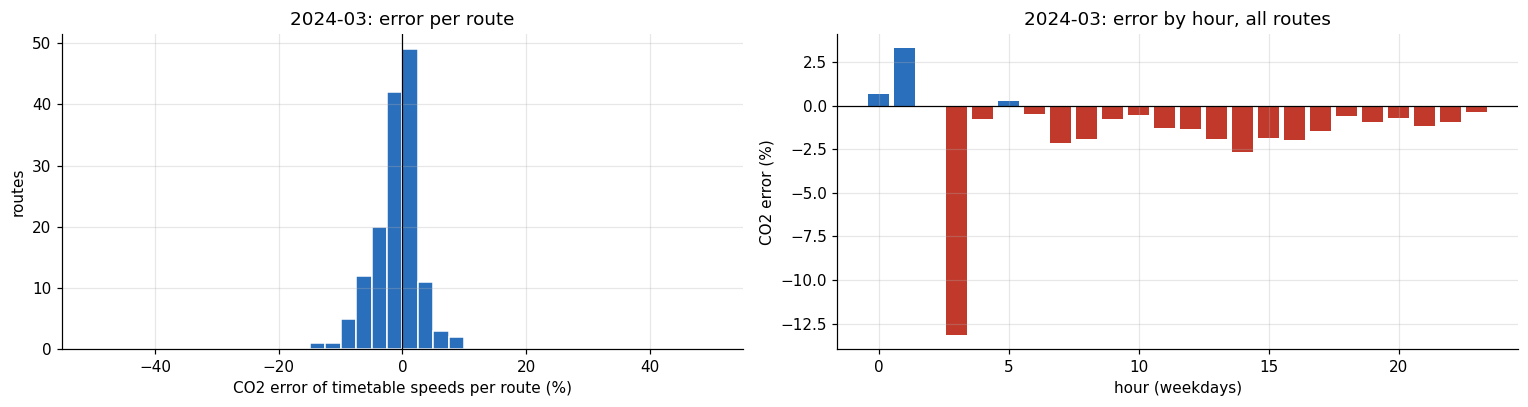

In [12]:
for month, s in results.items():
    per_route = (emis_tab(s, "route_id").filter(pl.col("bus_km") >= 500)
                    .select("route_id", "bus_km", "CO2_error", "NOx_error"))
    seg_err = (s.group_by("gtfs_route", "dir", "from_stop", "to_stop")
                .agg(km=pl.col("km").sum(), tt=pl.col("CO2_tt").sum(), act=pl.col("CO2_act").sum())
                .filter(pl.col("km") >= 20).with_columns(err=(pl.col("tt") - pl.col("act")) / pl.col("act")))
    print(f"{month}: routes with |CO2 error| > 10%: {(per_route['CO2_error'].abs() > .10).mean():.0%} of {per_route.height}; "
          f"> 20%: {(per_route['CO2_error'].abs() > .20).mean():.0%}")
    print(f"{month}: road segments with |CO2 error| > 10%: {(seg_err['err'].abs() > .10).mean():.0%} of {seg_err.height}; "
          f"> 25%: {(seg_err['err'].abs() > .25).mean():.0%}  "
          f"(underestimated: {(seg_err['err'] < -.10).mean():.0%}, overestimated: {(seg_err['err'] > .10).mean():.0%})")

s = results[list(results)[0]]
m0 = list(results)[0]
per_route = emis_tab(s, "route_id").filter(pl.col("bus_km") >= 500)
hourly = (s.filter(pl.col("weekday")).group_by("hour").agg(tt=pl.col("CO2_tt").sum(), act=pl.col("CO2_act").sum())
           .with_columns(err=(pl.col("tt") - pl.col("act")) / pl.col("act")).sort("hour"))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(per_route["CO2_error"] * 100, bins=np.arange(-50, 51, 2.5), color="#2a6fbb", edgecolor="white")
ax[0].axvline(0, color="k", lw=.8)
ax[0].set_xlabel("CO2 error of timetable speeds per route (%)"); ax[0].set_ylabel("routes")
ax[0].set_title(f"{m0}: error per route")
ax[1].bar(hourly["hour"], hourly["err"] * 100, color=["#c0392b" if v < 0 else "#2a6fbb" for v in hourly["err"].to_list()])
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xlabel("hour (weekdays)"); ax[1].set_ylabel("CO2 error (%)"); ax[1].set_title(f"{m0}: error by hour, all routes")
plt.tight_layout(); savefig(fig, "B3_route_hour_error"); plt.show()

## Conclusion
**Part A — the speed error is large and systematic.** About half of all trips run more than 10% slower than the
timetable between the first and last mid-route timepoint, on almost every route, at every daytime hour, in every
year. The timetable overstates mid-route speed and understates last-segment speed (padding).

**Part B — its effect on emissions depends on the level of detail:**
- **City-wide and per-route totals barely change** (about 1%): mid-route underestimates and padded last-segment
  overestimates cancel within almost every route.
- **Mid-route vs. last segment:** mid-route emissions are underestimated by about 5% (CO2) and 7–8% (NOx); last
  segments are overestimated by about 18% (CO2) and 30% (NOx).
- **Individual road segments (hotspot maps):** about 40% of road segments are off by more than 10% in CO2, and about
  10% by more than 25% — some under-, some overestimated.

So AI 1 matters for **where and when** emissions happen (maps, hotspots, segments near terminals, NOx), for routes
and days without history, and for forecasts — not for changing a city's or a route's total CO2.

*Limits:* emission factors are MOVES hot-running factors as implemented in gtfs2emis 0.1.2 (fleet average, reference
year 2020; average-speed bins); segments are timepoint-to-timepoint (gtfs2emis works stop-to-stop); "real speed" is
the average over a segment, not second-by-second driving; distances come from GTFS shapes of one feed per month.